# Population, Income and Rideshare Use per Community Area

Goal: add population and income to each of the 77 community areas, so we can compare areas fairly by **trips per person** instead of total trips. This feeds the transit-gap score (#16).

Data:
- ACS 5-year data by community area (City of Chicago, `t68z-cikk`): population
- Socioeconomic indicators by community area (`kn9c-c2s2`, 2008–2012): per capita income, % of households below poverty, hardship index
- Trips per area from `results/kmeans_area_clusters.csv` (cleaned trips from Jan 2023 to Aug 2026, by pickup area)
- Distance to the 'L' from `results/cta_access_by_area.csv`

In [1]:
from pathlib import Path
import re
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SUP = ROOT / "data" / "raw" / "supporting"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
key = lambda s: re.sub(r"[^A-Z]", "", str(s).upper()).replace("THELOOP", "LOOP")

access = pd.read_csv(ROOT / "results" / "cta_access_by_area.csv")
access["name"] = access["name"].replace({"Ohare": "O'Hare"})
clusters = pd.read_csv(ROOT / "results" / "kmeans_area_clusters.csv")[["area", "cluster", "trips"]]

acs = pd.read_csv(SUP / "acs_by_area.csv")
print(len(acs), "rows")
print(acs.columns.tolist())

77 rows
['ACS Year', 'Community Area', 'Under $25,000', '$25,000 to $49,999', '$50,000 to $74,999', '$75,000 to $125,000', '$125,000 +', 'Male 0 to 17', 'Male 18 to 24', 'Male 25 to 34', 'Male 35 to 49', 'Male 50 to 64', 'Male 65+', 'Female 0 to 17', 'Female 18 to 24', 'Female 25 to 34', 'Female 35 to 49', 'Female 50 to 64', 'Female 65 +', 'Total Population', 'White', 'Black or African American', 'American Indian or Alaska Native', 'Asian', 'Native Hawaiian or Pacific Islander', 'Other Race', 'Multiracial', 'White Not Hispanic or Latino', 'Hispanic or Latino', 'Record ID']


Check the printed column list: there should be a community area column and a total population column. If the dataset has several ACS years, the next cell keeps the latest one.

In [2]:
year_col = next((c for c in acs.columns if "year" in c.lower()), None)
if year_col:
    print("ACS years:", sorted(acs[year_col].unique()))
    acs = acs[acs[year_col] == acs[year_col].max()]
area_col = next(c for c in acs.columns if "community" in c.lower())
pop_col = next((c for c in acs.columns if "total population" in c.lower()),
               next(c for c in acs.columns if "population" in c.lower()))
print("area column:", area_col, "| population column:", pop_col)

pop = acs[[area_col, pop_col]].rename(columns={pop_col: "population"})
pop["population"] = pd.to_numeric(pop["population"].astype(str).str.replace(",", ""), errors="coerce")
if pd.api.types.is_numeric_dtype(pop[area_col]):
    pop = pop.rename(columns={area_col: "area"})
else:
    pop["k"] = pop[area_col].map(key)
    pop = pop.merge(access[["area", "name"]].assign(k=access["name"].map(key)), on="k", how="left")
    missing = pop[pop["area"].isna()][area_col].tolist()
    print("names with no match:", missing)
pop = pop.dropna(subset=["area"]).astype({"area": int}).groupby("area", as_index=False)["population"].sum()
print(len(pop), "areas with population; total population:", f"{pop.population.sum():,.0f}")   # 77 and about 2.65 million

ACS years: [np.int64(2023)]
area column: Community Area | population column: Total Population
names with no match: []
77 areas with population; total population: 2,647,621


In [3]:
soc = pd.read_csv(SUP / "socioeconomic_by_area.csv")
soc.columns = soc.columns.str.strip().str.upper()
pick = lambda word: next(c for c in soc.columns if word in c)
soc = soc.rename(columns={pick("NUMBER"): "area", pick("PER CAPITA INCOME"): "per_capita_income",
                          pick("BELOW POVERTY"): "pct_below_poverty", pick("HARDSHIP"): "hardship_index"})
soc = soc.dropna(subset=["area"]).astype({"area": int})   # drops the last row (whole city)
soc = soc[["area", "per_capita_income", "pct_below_poverty", "hardship_index"]]
print(len(soc), "areas with income")   # 77

77 areas with income


## Trips per person

In [4]:
YEARS = (pd.Timestamp("2026-08-31") - pd.Timestamp("2023-01-01")).days / 365.25   # about 3.67 years of trips
df = (access[["area", "name", "dist_to_L_km", "l_stations"]]
      .merge(pop, on="area").merge(soc, on="area").merge(clusters, on="area"))
df["trips_per_person_year"] = df["trips"] / df["population"] / YEARS
assert len(df) == 77, f"expected 77 areas, got {len(df)}"
df.to_csv(ROOT / "results" / "area_population_income.csv", index=False)
print("saved results/area_population_income.csv")
print(f"City average: {df.trips.sum() / df.population.sum() / YEARS:.1f} trips per person per year")
df.sort_values("trips_per_person_year", ascending=False)[
    ["name", "population", "trips_per_person_year", "per_capita_income", "dist_to_L_km", "cluster"]].round(1).head(10)

saved results/area_population_income.csv
City average: 30.7 trips per person per year


,name,population,trips_per_person_year,per_capita_income,dist_to_L_km,cluster
75,O'Hare,16281,268.4,25828,0.9,2
31,Loop,38284,173.3,65526,0.1,0
7,Near North Side,91635,132.7,88669,0.4,0
27,Near West Side,65370,106.2,44689,0.4,0
40,Hyde Park,24092,71.7,39056,1.9,0
32,Near South Side,26307,66.3,59077,0.7,0
6,Lincoln Park,62067,62.6,71551,0.4,0
5,Lake View,90652,56.6,60058,0.4,0
23,West Town,86453,46.7,43198,0.8,0
36,Fuller Park,2186,39.9,10432,0.2,1


In [5]:
df.sort_values("trips_per_person_year")[
    ["name", "population", "trips_per_person_year", "per_capita_income", "dist_to_L_km", "cluster"]].round(1).head(10)

,name,population,trips_per_person_year,per_capita_income,dist_to_L_km,cluster
51,East Side,23629,2.7,17104,7.6,1
73,Mount Greenwood,19107,4.7,34381,8.0,1
54,Hegewisch,8895,6.1,22677,9.4,1
63,Clearing,24710,6.1,25113,2.7,1
11,Forest Glen,19763,6.4,44164,2.6,1
16,Dunning,42548,6.8,26282,4.0,1
61,West Elsdon,18201,7.1,15754,0.8,1
62,Gage Park,34650,7.3,12171,1.2,1
64,West Lawn,32451,7.4,16907,2.1,1
8,Edison Park,11398,7.8,40959,2.8,0


Leaving out O'Hare, which is mostly an airport with only 16,281 residents, the Loop has the most trips per person (173 per year), followed by the Near North Side (133) and the Near West Side (106). The fewest are in East Side (2.7), Mount Greenwood (4.7) and Hegewisch (6.1), so the Loop has about 64 times more trips per person than East Side. 9 of the 10 lowest areas are in Cluster 1 (Edison Park is the only exception), and the three lowest are also the three areas farthest from the 'L' (7.6 to 9.4 km), but a few low ones like West Elsdon and Gage Park are only about 1 km from a station.

## Map of trips per person

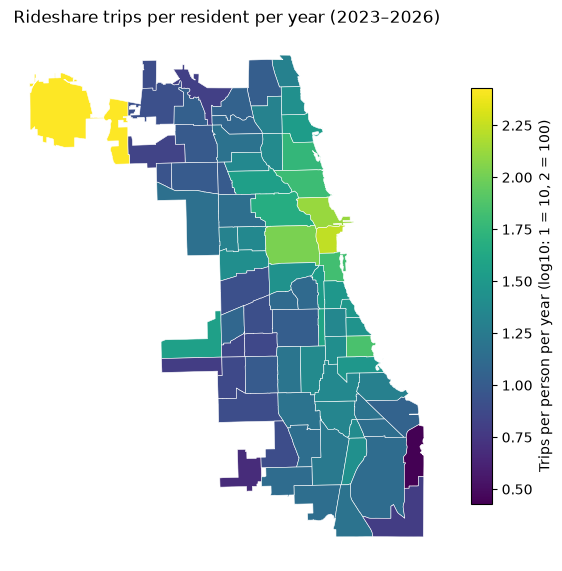

In [6]:
import numpy as np
areas = gpd.read_file(SUP / "community_areas.geojson")
num_col = [c for c in areas.columns if c.lower().startswith("area_num")][0]
areas["area"] = areas[num_col].astype(float).astype(int)
m = areas.merge(df[["area", "trips_per_person_year"]], on="area")
m["log10_trips_pp"] = np.log10(m["trips_per_person_year"])
ax = m.plot(column="log10_trips_pp", cmap="viridis", legend=True, figsize=(7, 9),
            edgecolor="white", linewidth=0.4,
            legend_kwds={"label": "Trips per person per year (log10: 1 = 10, 2 = 100)", "shrink": 0.6})
ax.set_axis_off()
ax.set_title("Rideshare trips per resident per year (2023–2026)")
plt.savefig(FIGS / "trips_per_person_map.png", dpi=150, bbox_inches="tight")
plt.show()

Trips per person are highest downtown and along the North Side lakefront (plus the two airports), and lowest on the Far South, Far Southwest and Northwest Sides. We use a log color scale because the values go from about 3 to over 250 trips per person, so on a normal scale O'Hare and the Loop would take up all the color and almost every other area would look the same.

## Income, 'L' access and rideshare use

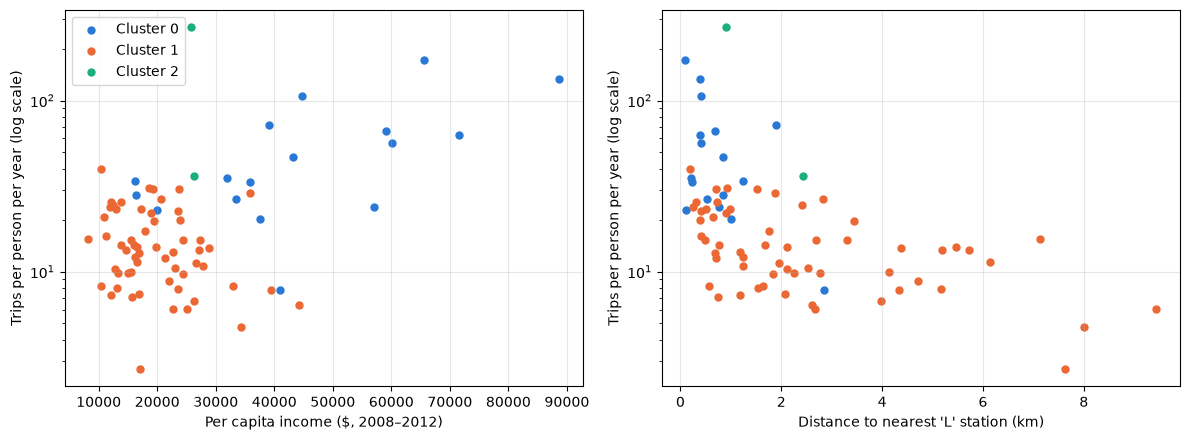

trips_per_person_year    1.00
per_capita_income        0.23
pct_below_poverty        0.28
hardship_index          -0.18
dist_to_L_km            -0.60
Name: trips_per_person_year, dtype: float64

In [7]:
colors = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, x, label in [(axes[0], "per_capita_income", "Per capita income ($, 2008–2012)"),
                     (axes[1], "dist_to_L_km", "Distance to nearest 'L' station (km)")]:
    for c, g in df.groupby("cluster"):
        ax.scatter(g[x], g["trips_per_person_year"], s=25, color=colors[c], label=f"Cluster {c}")
    ax.set_yscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Trips per person per year (log scale)")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGS / "income_access_vs_trips.png", dpi=150, bbox_inches="tight")
plt.show()

corr = df[["trips_per_person_year", "per_capita_income", "pct_below_poverty", "hardship_index", "dist_to_L_km"]].corr(method="spearman")
corr["trips_per_person_year"].round(2)

Richer areas use rideshare a little more per person, but the link is weak (Spearman 0.23 for income, and poverty and hardship are also weak at 0.28 and -0.18). Distance to the 'L' has a much stronger link (Spearman -0.60): areas farther from a station take fewer rideshare trips per person, so the areas with the best train access also use rideshare the most. The income data is from 2008–2012, about ten years older than the 2023–2026 trips, so some areas may have changed since then.

## What this means for the project

- The transit-gap score should use trips per person instead of total trips, together with distance to the 'L' and income. High trips per person on its own mostly points to downtown, where the 'L' is already good, so the score should give more weight to areas that are far from the 'L' and lower-income but still use rideshare.
- The areas that look like real transit gaps are lower-income Cluster 1 areas more than 2 km from the 'L' that still take more trips per person than the Cluster 1 median (13.3), such as Pullman (26.6), South Shore (19.7), Riverdale (15.5, with 56.5% of households below poverty), Auburn Gresham (15.4) and West Pullman (13.8).